# Milestone 4: Modeling, Comparison and Results
**Project:** Energy Efficient AI  |  **Input:** `../data/prepared/` (from Milestone 3)  |  **Target:** `efficiency_class` (Low = 0, Moderate = 1, High = 2)

**What this notebook does**
1. Loads the prepared train and test sets (already split and scaled in Milestone 3).
2. Chooses four models and a baseline, and says why.
3. Compares all models fairly: same split, same metrics, 5-fold cross validation on the train set, then one test score.
4. Runs the comparison on two feature sets, because Milestone 3 showed that two columns almost define the class.
5. Chooses the final model and justifies it, then checks its errors, its rules and its learning curve.
6. Lists the challenges, the limits of the final model and the planned improvements.

## Step 0: Setup

In [1]:
# Import libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")      # keep the output clean
os.makedirs("figures", exist_ok=True)  # folder for saved charts
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42                      # same seed everywhere, so results can be repeated

## Step 1: Load the prepared data

In [2]:
# Load the sets created in Milestone 3. The features are already scaled (fit on the train set only).
DATA = "../data/prepared/"
X_train = pd.read_csv(DATA + "X_train.csv")
X_test = pd.read_csv(DATA + "X_test.csv")
y_train = pd.read_csv(DATA + "y_train.csv").iloc[:, 0]
y_test = pd.read_csv(DATA + "y_test.csv").iloc[:, 0]

class_names = {0: "Low", 1: "Moderate", 2: "High"}
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Any missing values:", bool(X_train.isna().any().any() or X_test.isna().any().any()))

counts = pd.DataFrame({
    "Train rows": y_train.map(class_names).value_counts(),
    "Test rows": y_test.map(class_names).value_counts(),
    "Test share": y_test.map(class_names).value_counts(normalize=True).round(3),
}).loc[["Low", "Moderate", "High"]]
counts

Train: (5733, 10) | Test: (1434, 10)
Any missing values: False


,Train rows,Test rows,Test share
efficiency_class,,,
Low,2377,595,0.415
Moderate,2895,724,0.505
High,461,115,0.080


In [3]:
# Baseline: a "model" that always predicts the most common class (Moderate).
# Any real model must beat this number. If it does not, it has learned nothing useful.
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_pred = baseline.predict(X_test)
print(f"Baseline accuracy: {accuracy_score(y_test, base_pred):.3f}")
print(f"Baseline macro-F1: {f1_score(y_test, base_pred, average='macro'):.3f}")

Baseline accuracy: 0.505
Baseline macro-F1: 0.224


## Step 2: Which models and why

| Model | Why we chose it | What we expect |
|---|---|---|
| **Logistic Regression** | Simple and explainable. It is the standard first model for classification. | Good if the classes can be separated by straight boundaries |
| **KNN** | Small and clean dataset (7,167 rows, 10 features). It needs scaled data, which we have. | Works only if similar rows have the same class |
| **Decision Tree** | Captures non-linear rules and can be read like a flowchart. | Strong if the class follows rules on a few columns |
| **Random Forest** | Many trees voting together. Usually the strongest raw performance. | Strong, but harder to explain than one tree |

We also keep the **baseline** (always predict Moderate) so every score has a reference point.

In [4]:
# Same settings for every comparison. We create fresh models each time so nothing carries over.
def make_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    }
print(list(make_models().keys()))

['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest']


## Step 3: Two feature sets

In Milestone 3 we found that the class is almost a simple rule on two columns:

| Condition | Class |
|---|---|
| `energy_consumption_kwh` > 6 | Low |
| `energy_consumption_kwh` <= 3 and `execution_time_ms` <= 150 | High |
| everything else | Moderate |

So a model that sees these two columns can score almost 100% just by learning the rule. To be honest about this, we compare the models twice:

- **Set A: all 10 features.** Shows what the models do when the rule columns are available.
- **Set B: without `energy_consumption_kwh` and `execution_time_ms`.** Shows how well the other 8 features can predict the class on their own.

In [5]:
rule_cols = ["energy_consumption_kwh", "execution_time_ms"]
feature_sets = {
    "A: all 10 features": list(X_train.columns),
    "B: without energy and time": [c for c in X_train.columns if c not in rule_cols],
}
for name, cols in feature_sets.items():
    print(f"{name}: {len(cols)} features")

A: all 10 features: 10 features
B: without energy and time: 8 features


## Step 4: Fair comparison with cross validation

**What makes the comparison fair**
- Same train/test split for every model.
- Same metrics for every model: **accuracy** and **macro-F1** (the average F1 of the three classes).
- Macro-F1 matters because High is only 8% of the data. Accuracy alone can hide a model that ignores High.
- **5-fold cross validation on the train set** gives a stable score. The **test set is used once** at the end, for the final number.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # keeps class shares in every fold

def evaluate(model, cols):
    # 1) cross validation on the train set only
    cv_result = cross_validate(model, X_train[cols], y_train, cv=cv, scoring=["accuracy", "f1_macro"])
    # 2) one fit on the full train set, one score on the test set
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    f1_each = f1_score(y_test, pred, average=None, labels=[0, 1, 2])
    return {
        "CV accuracy": cv_result["test_accuracy"].mean(),
        "CV std": cv_result["test_accuracy"].std(),
        "CV macro-F1": cv_result["test_f1_macro"].mean(),
        "Test accuracy": accuracy_score(y_test, pred),
        "Test macro-F1": f1_score(y_test, pred, average="macro"),
        "Test F1 (High)": f1_each[2],
    }

rows = []
for set_name, cols in feature_sets.items():
    # baseline row first, so every set has its reference
    rows.append({"Feature set": set_name, "Model": "Baseline (always Moderate)", **evaluate(DummyClassifier(strategy="most_frequent"), cols)})
    for model_name, model in make_models().items():
        rows.append({"Feature set": set_name, "Model": model_name, **evaluate(model, cols)})

results = pd.DataFrame(rows)
print("Done:", len(results), "rows")

Done: 10 rows


In [7]:
# Set A: all 10 features
results[results["Feature set"].str.startswith("A")].drop(columns="Feature set").round(3).reset_index(drop=True)

,Model,CV accuracy,CV std,CV macro-F1,Test accuracy,Test macro-F1,Test F1 (High)
0,Baseline (always Moderate),0.505,0.000,0.224,0.505,0.224,0.000
1,Logistic Regression,0.969,0.004,0.928,0.971,0.935,0.838
2,KNN,0.858,0.008,0.784,0.874,0.818,0.670
3,Decision Tree,0.999,0.001,0.998,0.999,0.998,0.996
4,Random Forest,0.999,0.001,0.998,0.999,0.998,0.996


In [8]:
# Set B: without energy and time
results[results["Feature set"].str.startswith("B")].drop(columns="Feature set").round(3).reset_index(drop=True)

,Model,CV accuracy,CV std,CV macro-F1,Test accuracy,Test macro-F1,Test F1 (High)
0,Baseline (always Moderate),0.505,0.000,0.224,0.505,0.224,0.000
1,Logistic Regression,0.505,0.000,0.224,0.505,0.224,0.000
2,KNN,0.461,0.015,0.319,0.450,0.310,0.000
3,Decision Tree,0.426,0.014,0.330,0.432,0.342,0.107
4,Random Forest,0.478,0.014,0.309,0.473,0.305,0.000


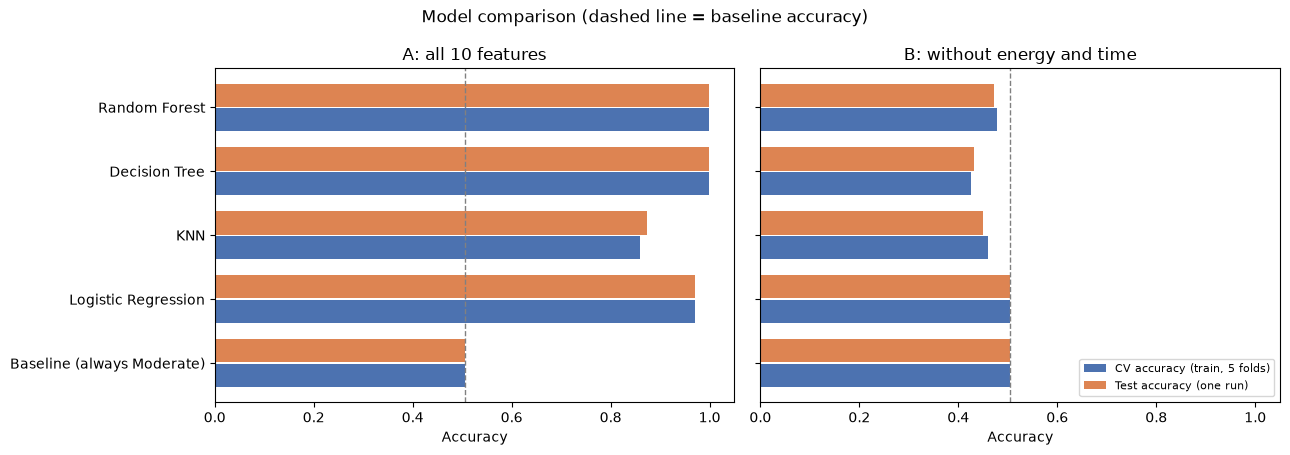

In [9]:
# Chart: cross-validated score next to the test score, for every model and both sets
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (set_name, _) in zip(axes, feature_sets.items()):
    part = results[results["Feature set"] == set_name].reset_index(drop=True)
    y = np.arange(len(part))
    ax.barh(y - 0.19, part["CV accuracy"], height=0.36, label="CV accuracy (train, 5 folds)", color="#4C72B0")
    ax.barh(y + 0.19, part["Test accuracy"], height=0.36, label="Test accuracy (one run)", color="#DD8452")
    ax.axvline(accuracy_score(y_test, base_pred), color="gray", linestyle="--", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(part["Model"])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.05)
    ax.set_xlabel("Accuracy")
    ax.set_title(set_name)
axes[1].legend(loc="lower right", fontsize=8)
fig.suptitle("Model comparison (dashed line = baseline accuracy)")
plt.tight_layout()
plt.savefig("figures/model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

**What the comparison shows**

- **Set A (all features):** Decision Tree and Random Forest are almost perfect and tied (the difference is smaller than the fold-to-fold spread). Logistic Regression is good but not perfect, and KNN is clearly weaker. The CV score and the test score agree closely for every model, so the results are stable and not a lucky split.
- **Set B (without energy and time):** every model is close to the baseline or below it. The best accuracy is about the same as always predicting Moderate, and the models almost never find the High class.
- The gap between A and B is the main finding. The class is defined by `energy_consumption_kwh` and `execution_time_ms`, not by the other 8 features.

## Step 5: Choose the final model

**Decision: Decision Tree, trained on all 10 features (Set A).**

| Reason | Detail |
|---|---|
| Best score | It ties with Random Forest at about 99.9% CV accuracy and 0.998 macro-F1. |
| Simplest model among the tied ones | When two models score the same, the simpler one is the safer choice. It is faster and fully explainable. |
| Explainable | We can print the whole tree and read the rules (Step 7). |
| Honest reading | We chose the model that recovers the rule. We do not claim it found hidden patterns. |

In [10]:
# Check the tie between Decision Tree and Random Forest on Set A
a = results[results["Feature set"].str.startswith("A")].set_index("Model")
dt, rf = a.loc["Decision Tree"], a.loc["Random Forest"]
print(f"CV accuracy: Decision Tree {dt['CV accuracy']:.4f} vs Random Forest {rf['CV accuracy']:.4f}")
print(f"Difference: {abs(dt['CV accuracy'] - rf['CV accuracy']):.4f}  (fold-to-fold spread is about {dt['CV std']:.4f})")

CV accuracy: Decision Tree 0.9991 vs Random Forest 0.9990
Difference: 0.0002  (fold-to-fold spread is about 0.0010)


## Step 6: Final results and error analysis

In [11]:
# Final model: Decision Tree on Set A, scored once on the test set
cols_a = feature_sets["A: all 10 features"]
final_model = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train[cols_a], y_train)
final_pred = final_model.predict(X_test[cols_a])

print(f"Test accuracy: {accuracy_score(y_test, final_pred):.4f}")
print(f"Test macro-F1: {f1_score(y_test, final_pred, average='macro'):.4f}")
print()
print(classification_report(y_test, final_pred, target_names=[class_names[i] for i in [0, 1, 2]], digits=3))

Test accuracy: 0.9993
Test macro-F1: 0.9983

              precision    recall  f1-score   support

         Low      1.000     1.000     1.000       595
    Moderate      0.999     1.000     0.999       724
        High      1.000     0.991     0.996       115

    accuracy                          0.999      1434
   macro avg      1.000     0.997     0.998      1434
weighted avg      0.999     0.999     0.999      1434



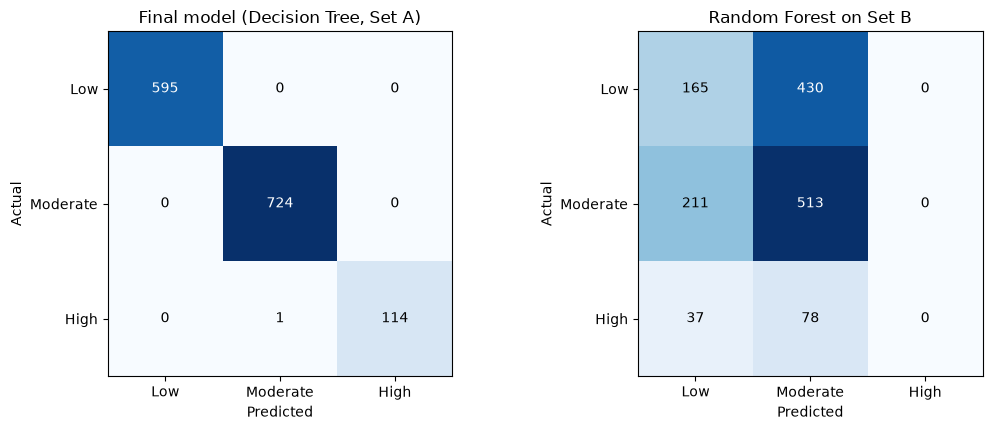

In [12]:
# Confusion matrix of the final model, and of the best Set B model (Random Forest) for comparison
def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(["Low", "Moderate", "High"]); ax.set_yticklabels(["Low", "Moderate", "High"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")

cols_b = feature_sets["B: without energy and time"]
rf_b = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE).fit(X_train[cols_b], y_train)
rf_b_pred = rf_b.predict(X_test[cols_b])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
plot_cm(axes[0], y_test, final_pred, "Final model (Decision Tree, Set A)")
plot_cm(axes[1], y_test, rf_b_pred, "Random Forest on Set B")
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()

In [13]:
# Error analysis: look at the rows the final model got wrong
wrong = X_test[cols_a][final_pred != y_test].copy()
wrong["actual"] = y_test[final_pred != y_test].map(class_names)
wrong["predicted"] = pd.Series(final_pred, index=y_test.index)[final_pred != y_test].map(class_names)
print(f"Wrong rows: {len(wrong)} out of {len(y_test)}")

# Convert the two rule columns back to real units to see how close they are to the rule limits
params = pd.read_csv(DATA + "scaler_params.csv").set_index("feature")
raw = wrong[["energy_consumption_kwh", "execution_time_ms"]] * params.loc[["energy_consumption_kwh", "execution_time_ms"], "std"] \
      + params.loc[["energy_consumption_kwh", "execution_time_ms"], "mean"]
pd.concat([raw.round(2), wrong[["actual", "predicted"]]], axis=1)

Wrong rows: 1 out of 1434


,energy_consumption_kwh,execution_time_ms,actual,predicted
671,3.0,25.41,High,Moderate


**Error analysis**

- The final model makes **1 mistake out of 1,434 test rows**. It is a High row whose energy is exactly 3.00, which is the rule limit. The tree learned its cut point from the train set, and this row falls on the other side of it.
- **Set B tells a different story.** The Random Forest without energy and time **never predicts High** (0 of the 115 High rows are found). Most rows go to Moderate. So it fails exactly where a real efficiency model would matter most.

## Step 7: Interpretation: what did the model learn?

In [14]:
# Read the splits of the final tree. The features are scaled, so we convert each limit back to real units.
t = final_model.tree_
print(f"Tree depth: {final_model.get_depth()} | leaves: {final_model.get_n_leaves()}")
print()
for node in range(t.node_count):
    if t.feature[node] >= 0:                       # internal node (leaves have feature = -2)
        name = cols_a[t.feature[node]]
        real_limit = t.threshold[node] * params.loc[name, "std"] + params.loc[name, "mean"]
        print(f"node {node}: split on {name} at {real_limit:.2f}")

Tree depth: 3 | leaves: 4

node 0: split on energy_consumption_kwh at 6.00
node 1: split on execution_time_ms at 150.00
node 2: split on energy_consumption_kwh at 3.00


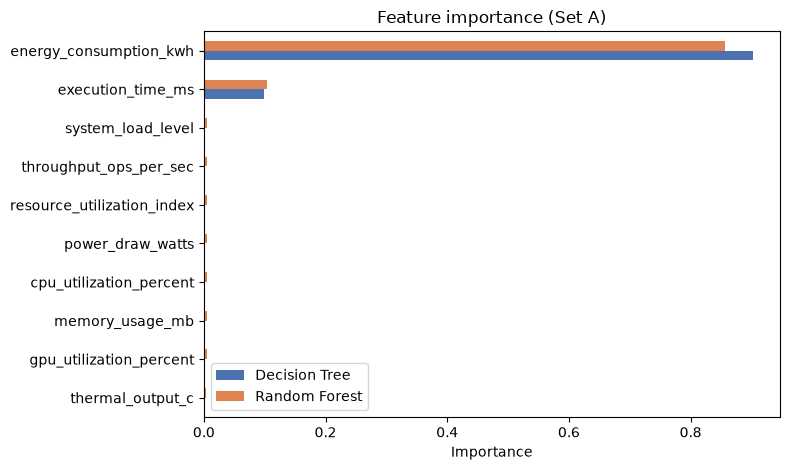

,Decision Tree,Random Forest
energy_consumption_kwh,0.902,0.856
execution_time_ms,0.098,0.104
system_load_level,0.000,0.006
throughput_ops_per_sec,0.000,0.005


In [15]:
# Feature importance: how much each feature was used (Decision Tree and Random Forest, Set A)
rf_a = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE).fit(X_train[cols_a], y_train)
imp = pd.DataFrame({
    "Decision Tree": final_model.feature_importances_,
    "Random Forest": rf_a.feature_importances_,
}, index=cols_a).sort_values("Random Forest")

ax = imp.plot.barh(figsize=(8, 4.8), color=["#4C72B0", "#DD8452"])
ax.set_xlabel("Importance")
ax.set_title("Feature importance (Set A)")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()
imp.sort_values("Random Forest", ascending=False).round(3).head(4)

**What the model learned**

- The tree is tiny: depth 3 and 4 leaves. It splits only on `energy_consumption_kwh` (near 6 and near 3) and `execution_time_ms` (near 150). These are the same limits we found by hand in Milestone 3.
- Both the tree and the forest give almost all the importance to these two columns. The other 8 features are close to zero.
- For the business: the model confirms that energy use and execution time decide the efficiency class. It does not explain what makes a run use less energy.

## Step 8: Learning curve of the final model

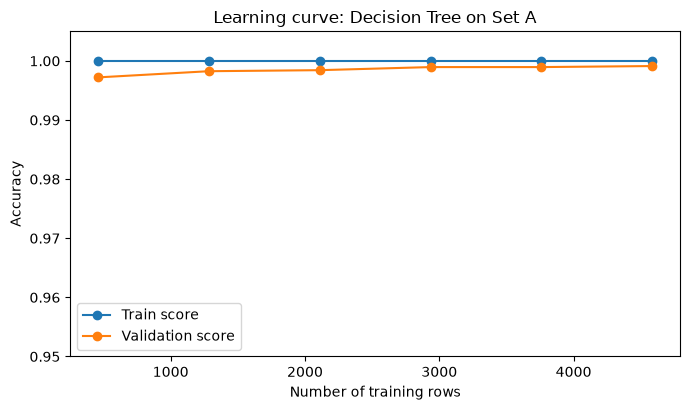

Validation score with 10% of the data: 0.9972
Validation score with 100% of the data: 0.9991


In [16]:
# Does the final model need more data? Train on 10% ... 100% of the train set and watch both scores.
sizes, train_scores, val_scores = learning_curve(
    DecisionTreeClassifier(random_state=RANDOM_STATE), X_train[cols_a], y_train,
    cv=cv, train_sizes=np.linspace(0.1, 1.0, 6), scoring="accuracy")

plt.figure(figsize=(7, 4.2))
plt.plot(sizes, train_scores.mean(axis=1), marker="o", label="Train score")
plt.plot(sizes, val_scores.mean(axis=1), marker="o", label="Validation score")
plt.xlabel("Number of training rows")
plt.ylabel("Accuracy")
plt.title("Learning curve: Decision Tree on Set A")
plt.ylim(0.95, 1.005)  # wide enough so a tiny gap does not look big
plt.legend()
plt.tight_layout()
plt.savefig("figures/learning_curve.png", dpi=120, bbox_inches="tight")
plt.show()
print("Validation score with 10% of the data:", round(val_scores.mean(axis=1)[0], 4))
print("Validation score with 100% of the data:", round(val_scores.mean(axis=1)[-1], 4))

**Reading the curve:** both curves end close together at a very high score. The gap is smaller than 0.1 percentage points, so there is no real overfitting and enough data for this model. More rows would not help. This is also what we expect when the class is a simple rule.

## Step 9: One improvement attempt on Set B

In [17]:
# Set B has a problem: the High class is rare (8%). Can class weights fix it?
# class_weight="balanced" gives more weight to the rare class during training.
attempts = {
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest (balanced, depth 8)": RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=RANDOM_STATE),
}
rows = []
for name, model in attempts.items():
    model.fit(X_train[cols_b], y_train)
    pred = model.predict(X_test[cols_b])
    rows.append({"Model": name,
                 "Test accuracy": accuracy_score(y_test, pred),
                 "Test macro-F1": f1_score(y_test, pred, average="macro"),
                 "Test F1 (High)": f1_score(y_test, pred, average=None, labels=[0, 1, 2])[2]})
pd.DataFrame(rows).round(3)

,Model,Test accuracy,Test macro-F1,Test F1 (High)
0,Logistic Regression (balanced),0.317,0.298,0.152
1,"Random Forest (balanced, depth 8)",0.375,0.322,0.112


**Result of the attempt:** class weights make the models predict High more often, but the accuracy falls below the baseline and the macro-F1 improves only a little. The other 8 features do not contain enough information about the class, so reweighting cannot fix it.

## Step 10: Summary

| Item | Result |
|---|---|
| Models compared | Logistic Regression, KNN, Decision Tree, Random Forest (plus a baseline) |
| Method | Same split, 5-fold cross validation on train, one test score, accuracy and macro-F1 |
| Final model | Decision Tree on all 10 features |
| Final performance | Test accuracy about 99.9%, macro-F1 about 0.998 (CV accuracy about 99.9%) |
| Without energy and time | Best accuracy about 50%, no better than the 50.5% baseline; High almost never found |

## Challenges we met

1. **The class is almost a rule.** Two columns define it, so the comparison on Set A cannot separate Decision Tree and Random Forest.
2. **Class imbalance.** High is only 8% of the data. Accuracy alone is misleading, so we also report macro-F1 and the F1 of High.
3. **Weak signal in the other 8 features.** Without energy and time, no model beats the baseline.

## Limits of the final model (be honest about these)

- It **recovers a rule**; it does not discover new patterns. Its 99.9% mostly tells us the label was built from two columns.
- Energy and execution time are only known **after** a run finishes. So the model cannot predict efficiency in advance, which is what a real user would want.
- The test set is small for the High class (115 rows), so any High score has a wide margin of error.

## Planned improvements

1. Ask where `efficiency_class` came from (how the data owner defined it). If it is a formula, we should say so in the project.
2. Look for features that **cause** energy use and run time (model size, batch size, hardware type). With these, a real prediction before the run becomes possible.
3. Try a tuned Random Forest or gradient boosting on Set B once better features exist, and keep the macro-F1 as the main metric.